In [1]:
%load_ext autoreload
%autoreload 2

# Imports
import sys; sys.path.append("..")
import io, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pywt                                   # pip install PyWavelets
from PIL import Image
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from sklearn.model_selection import StratifiedGroupKFold
from src.datos import DATA, a_gris
from src.preproceso import preprocesar, mascara_cerebral, normalizar, a_tamano_comun
from src.segmentacion import umbral_adaptativo
from src.caracteristicas import medidas_corte, glcm_features, region_profunda
from src.clasificacion import preparar, CARACTERISTICAS, modelo_logistica, metricas, SEMILLA, K

# scikit-image >= 0.26 avisa que el parámetro min_size de remove_small_objects va a cambiar de nombre
warnings.filterwarnings("ignore", category=FutureWarning)

## 6.1 Cortes de prueba y clasificador de referencia

In [2]:
# Mismos datos que el notebook 05. Se separa una partición de grupos completa (la primera de las 5 de
# StratifiedGroupKFold) como prueba: el clasificador se entrena con las imágenes originales del resto.
feat = pd.read_csv(Path("..") / "data" / "caracteristicas_cortes.csv")
datos = preparar(feat)
y = datos["y"].to_numpy()
tr, te = next(StratifiedGroupKFold(K, shuffle=True, random_state=SEMILLA).split(datos, y, datos["Grupo"]))
clf = modelo_logistica("balanced").fit(datos.loc[tr, CARACTERISTICAS].to_numpy(), y[tr])
print(f"Entrenamiento: {len(tr)} cortes | prueba: {len(te)} cortes")
assert not set(datos.loc[tr, "Grupo"]) & set(datos.loc[te, "Grupo"])

# Como el pipeline se repite 13 veces por corte, se toma una muestra de 75 cortes de prueba por Clase y Eje
N_POR_ESTRATO = 75
muestra = datos.loc[te].groupby(["Clase", "Eje"]).sample(N_POR_ESTRATO, random_state=SEMILLA).reset_index(drop=True)
muestra.groupby(["Clase", "Eje"]).size().unstack()

Entrenamiento: 2209 cortes | prueba: 551 cortes


Eje,Axial,Sagital
Clase,,
Control,75,75
MS,75,75


## 6.2 Compresión JPEG

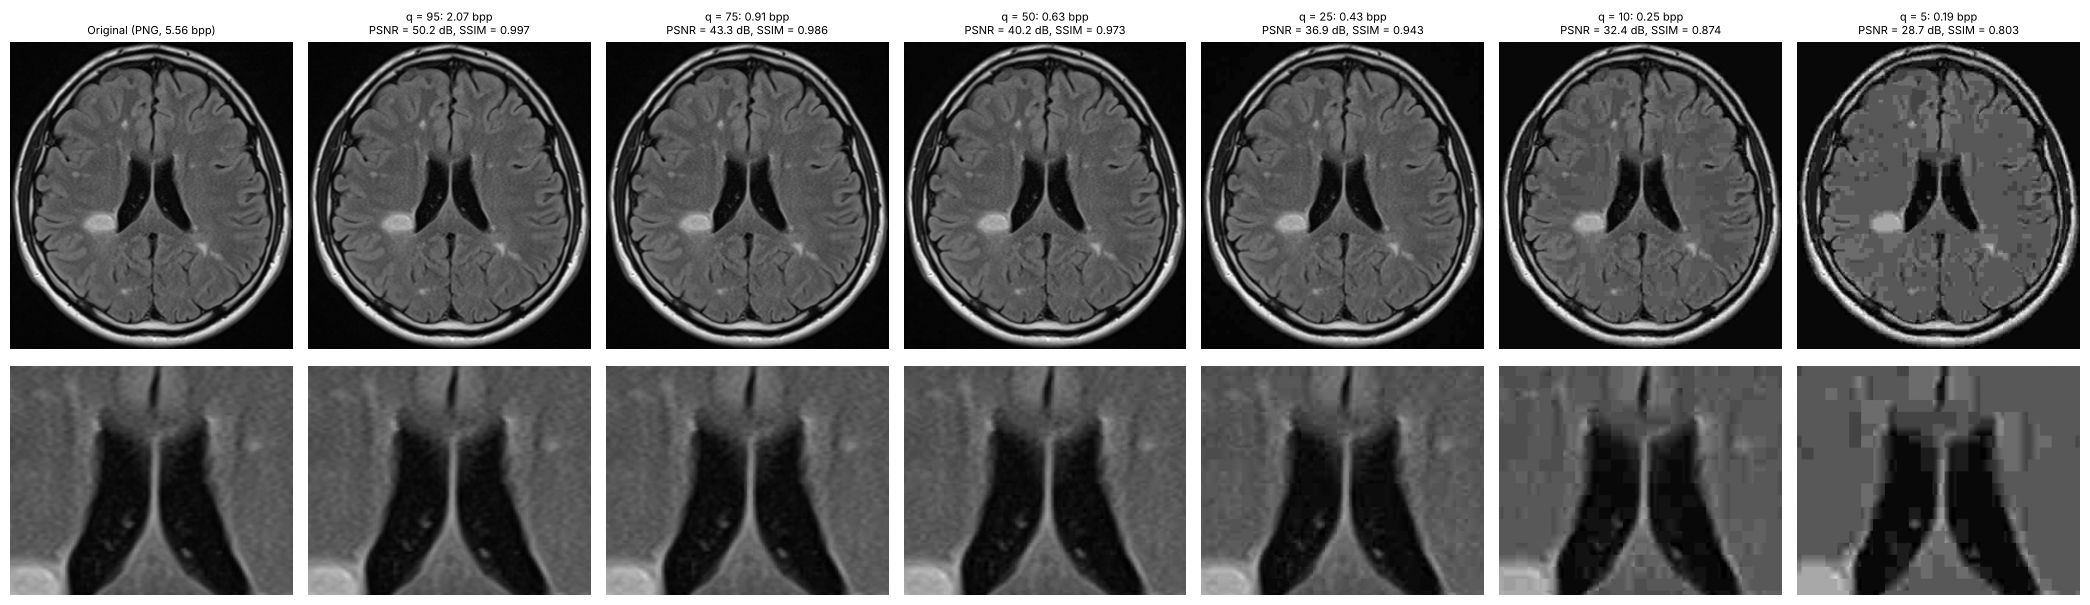

In [3]:
CALIDADES_JPEG = [95, 75, 50, 25, 10, 5]     # parámetro quality de Pillow

def comprimir_jpeg(img, calidad):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=calidad)
    datos_jpg = buf.getvalue()
    rec = np.asarray(Image.open(io.BytesIO(datos_jpg)).convert("L"))
    return rec, 8 * len(datos_jpg) / img.size          # imagen reconstruida y bits por píxel

# Ejemplo: corte de MS con lesión periventricular evidente (usado en el notebook 03), con ampliación
EJEMPLO = DATA / "MS Axial_crop" / "A1 (505).png"
img = a_gris(EJEMPLO)
h, w = img.shape
zoom = (slice(int(0.30 * h), int(0.60 * h)), slice(int(0.30 * w), int(0.70 * w)))

fig, axs = plt.subplots(2, len(CALIDADES_JPEG) + 1, figsize=(3 * (len(CALIDADES_JPEG) + 1), 6.5))
axs[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axs[0, 0].set_title(f"Original (PNG, {8 * EJEMPLO.stat().st_size / img.size:.2f} bpp)", fontsize=8)
axs[1, 0].imshow(img[zoom], cmap="gray", vmin=0, vmax=255)
for j, q in enumerate(CALIDADES_JPEG, start=1):
    rec, bpp = comprimir_jpeg(img, q)
    axs[0, j].imshow(rec, cmap="gray", vmin=0, vmax=255)
    axs[0, j].set_title(f"q = {q}: {bpp:.2f} bpp\nPSNR = {peak_signal_noise_ratio(img, rec, data_range=255):.1f} dB, "
                        f"SSIM = {structural_similarity(img, rec, data_range=255):.3f}", fontsize=8)
    axs[1, j].imshow(rec[zoom], cmap="gray", vmin=0, vmax=255)
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

&ensp; Se comprimió cada imagen original (8 bits, niveles de gris) en JPEG con Pillow, a seis calidades (`quality` = 95, 75, 50, 25, 10 y 5), y se volvió a decodificar. La tasa se mide en **bits por píxel (bpp)** del archivo JPEG real. En el corte de ejemplo (`A1 (505)`, 5,56 bpp en PNG) va de 2,07 bpp con q = 95 a 0,19 bpp con q = 5.

**Observación.** Hasta q = 25 (0,43 bpp, PSNR = 36,9 dB) la imagen es prácticamente indistinguible de la original, aun en la ampliación. Desde q = 10 aparecen los **bloques de 8 × 8 píxeles** típicos de JPEG: la sustancia blanca queda en parches planos, con saltos de intensidad entre bloques. La lesión periventricular grande sigue siendo visible en todos los niveles.

**Limitación.** El parámetro `quality` no es una escala lineal de tasa ni de calidad, y la tasa obtenida depende del contenido de cada imagen.

## 6.3 Compresión con wavelets

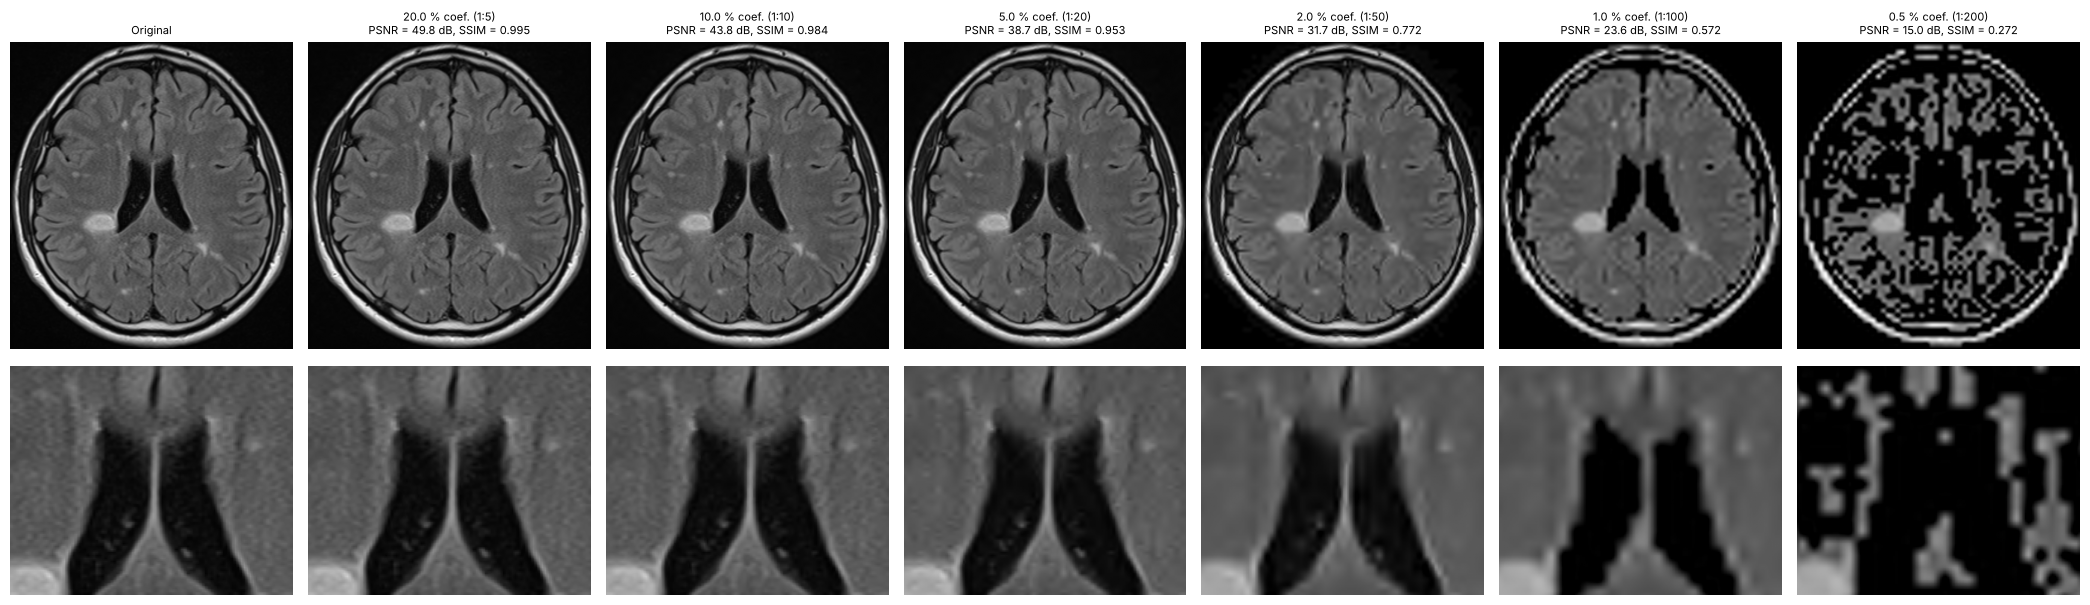

In [4]:
FRACCIONES_WAVELET = [0.20, 0.10, 0.05, 0.02, 0.01, 0.005]   # fracción de coeficientes que se conservan
WAVELET = "bior4.4"        # biortogonal 9/7 (CDF), la de JPEG 2000 con pérdida
NIVELES_WAVELET = 3

def comprimir_wavelet(img, fraccion, wavelet=WAVELET, nivel=NIVELES_WAVELET):
    coefs = pywt.wavedec2(img.astype(float), wavelet, level=nivel, mode="periodization")
    arr, cortes = pywt.coeffs_to_array(coefs)
    k = max(1, int(round(fraccion * arr.size)))
    umbral = np.partition(np.abs(arr).ravel(), -k)[-k]          # magnitud del k-ésimo coeficiente más grande
    arr[np.abs(arr) < umbral] = 0                                # umbral duro: el resto se anula
    rec = pywt.waverec2(pywt.array_to_coeffs(arr, cortes, output_format="wavedec2"), wavelet, mode="periodization")
    rec = rec[:img.shape[0], :img.shape[1]]
    return np.clip(np.round(rec), 0, 255).astype(np.uint8), np.count_nonzero(arr) / arr.size

fig, axs = plt.subplots(2, len(FRACCIONES_WAVELET) + 1, figsize=(3 * (len(FRACCIONES_WAVELET) + 1), 6.5))
axs[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axs[0, 0].set_title("Original", fontsize=8)
axs[1, 0].imshow(img[zoom], cmap="gray", vmin=0, vmax=255)
for j, f in enumerate(FRACCIONES_WAVELET, start=1):
    rec, frac = comprimir_wavelet(img, f)
    axs[0, j].imshow(rec, cmap="gray", vmin=0, vmax=255)
    axs[0, j].set_title(f"{100 * frac:.1f} % coef. (1:{1 / frac:.0f})\nPSNR = {peak_signal_noise_ratio(img, rec, data_range=255):.1f} dB, "
                        f"SSIM = {structural_similarity(img, rec, data_range=255):.3f}", fontsize=8)
    axs[1, j].imshow(rec[zoom], cmap="gray", vmin=0, vmax=255)
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

&ensp; Se aplicó una transformada wavelet 2D con la wavelet biortogonal 9/7 (`bior4.4`, la de JPEG 2000 con pérdida) en 3 niveles. Se conservó una fracción de los coeficientes de mayor magnitud (20 %, 10 %, 5 %, 2 %, 1 % y 0,5 %), se anularon los demás (umbral duro), se reconstruyó y se redondeó a 8 bits. La tasa de compresión es **nominal** (1 / fracción: de 1:5 a 1:200), porque no se codificaron los coeficientes ni sus posiciones.

**Observación.** Hasta el 5 % (1:20) la imagen se ve bien. Al 2 % (1:50) se suaviza: se pierde la textura fina y los bordes quedan borrosos, pero sin bloques. Al 1 % (1:100) aparecen oscilaciones (*ringing*) alrededor de los bordes fuertes, como el cráneo y los ventrículos. **Al 0,5 % la imagen se destruye**: con 3 niveles, la banda de aproximación ocupa 1/64 ≈ 1,6 % de los coeficientes, así que conservar menos del 1,6 % obliga a descartar parte de la propia aproximación (las bajas frecuencias). A diferencia de JPEG, las wavelets degradan suavizando, no en bloques.

**Limitaciones.** Con tasas nominales, la comparación con JPEG favorece a las wavelets: un codificador real (cuantización y codificación de los coeficientes) necesitaría más bits. La fracción de coeficientes conservados se aplica a toda la imagen, incluido el fondo.

## 6.4 Pipeline completo sobre las imágenes comprimidas

In [5]:
def calidad_imagen(original, comprimida):
    return {"PSNR": peak_signal_noise_ratio(original, comprimida, data_range=255),
            "SSIM": structural_similarity(original, comprimida, data_range=255)}

def preprocesar_img(img):        # igual que preprocesar(ruta), pero recibe la imagen ya leída
    m = mascara_cerebral(img)
    z = a_tamano_comun(np.where(m, normalizar(img, m), 0))
    return z, a_tamano_comun(m, orden=0) > 0.5

def dice(a, b):
    s = a.sum() + b.sum()
    return 2 * np.logical_and(a, b).sum() / s if s else np.nan

# preprocesar_img tiene que dar lo mismo que preprocesar(ruta) sobre la imagen original
for ruta in muestra["Ruta"].iloc[:10]:
    z1, m1 = preprocesar(DATA / ruta)
    z2, m2 = preprocesar_img(a_gris(DATA / ruta))
    assert np.array_equal(z1, z2) and np.array_equal(m1, m2)
print("preprocesar_img coincide con preprocesar")

preprocesar_img coincide con preprocesar


In [6]:
# Para cada corte: pipeline sobre la original y sobre cada nivel de compresión. Se guardan la calidad de imagen,
# el Dice de la máscara y de la segmentación contra los de la original, y las características del notebook 04
def evaluar_corte(img, niveles_jpeg=CALIDADES_JPEG, niveles_wavelet=FRACCIONES_WAVELET):
    z0, m0 = preprocesar_img(img)
    s0 = umbral_adaptativo(z0, m0)
    filas = [{"Metodo": "Original", "Nivel": "-", "Tasa": np.nan, "PSNR": np.inf, "SSIM": 1.0,
              "Dice_mascara": 1.0, "Dice_seg": dice(s0, s0),
              **medidas_corte(m0, s0), **glcm_features(z0, region_profunda(m0, s0))}]
    variantes = [("JPEG", q, comprimir_jpeg, q) for q in niveles_jpeg] + \
                [("Wavelet", f, comprimir_wavelet, f) for f in niveles_wavelet]
    for metodo, nivel, funcion, param in variantes:
        rec, tasa = funcion(img, param)
        z, m = preprocesar_img(rec)
        s = umbral_adaptativo(z, m)
        filas.append({"Metodo": metodo, "Nivel": nivel, "Tasa": tasa, **calidad_imagen(img, rec),
                      "Dice_mascara": dice(m0, m), "Dice_seg": dice(s0, s),
                      **medidas_corte(m, s), **glcm_features(z, region_profunda(m, s))})
    return filas

CSV_COMP = Path("..") / "data" / "compresion_muestra.csv"
if CSV_COMP.exists():
    comp = pd.read_csv(CSV_COMP)
    print("Cargado desde", CSV_COMP)
else:
    t0 = time.time()
    filas = []
    for _, r in muestra.iterrows():
        for fila in evaluar_corte(a_gris(DATA / r["Ruta"])):
            filas.append({"Ruta": r["Ruta"], "Clase": r["Clase"], "Eje": r["Eje"], **fila})
    comp = pd.DataFrame(filas)
    comp.to_csv(CSV_COMP, index=False)
    print(f"Calculado en {(time.time() - t0) / 60:.1f} min y guardado en {CSV_COMP}")
comp["Nivel"] = comp["Nivel"].astype(str)
print(len(comp), "filas =", comp["Ruta"].nunique(), "cortes x", comp.groupby("Ruta").size().iloc[0], "versiones")

Calculado en 7.5 min y guardado en ../data/compresion_muestra.csv
3900 filas = 300 cortes x 13 versiones


In [7]:
# Comprobación: las características de la versión original coinciden con las del CSV del notebook 04
orig = comp[comp["Metodo"] == "Original"].set_index("Ruta")
ref = feat.set_index("Ruta").loc[orig.index]
cols = ["Area_cerebro", "N_regiones", "Area_lesion", "Area_rel"] + ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]
assert np.allclose(orig[cols].to_numpy(float), ref[cols].to_numpy(float), equal_nan=True)
print("La versión original reproduce el CSV del notebook 04")

La versión original reproduce el CSV del notebook 04


&ensp; Para cada uno de los **300 cortes de prueba** (75 por clase y eje, tomados de una partición de grupos que el clasificador no vio al entrenar) se corrió el pipeline completo del notebook 04 sobre la imagen original y sobre las 12 versiones comprimidas: máscara, normalización, segmentación, medidas y textura. Por cada versión se guardaron el PSNR y el SSIM contra la original, el Dice de la máscara y de la segmentación contra los de la original, y todas las características. En total son 3900 filas (300 cortes × 13 versiones), calculadas en 7,5 min y guardadas en `data/compresion_muestra.csv`.

**Comprobaciones.** `preprocesar_img`, que recibe la imagen ya leída para poder pasarle la comprimida, da exactamente lo mismo que `preprocesar(ruta)`. Las características de la versión original reproducen las del CSV del notebook 04.

**Limitación.** Por el costo de repetir el pipeline 13 veces por corte, se usó una muestra de 300 cortes y no el dataset completo.

## 6.5 Calidad de imagen

In [8]:
# Tasa de compresión respecto de la imagen sin comprimir a 8 bits por píxel. En JPEG es real (tamaño del archivo);
# en wavelets es nominal (1 / fracción de coeficientes), porque no se codificaron los coeficientes.
cmp = comp[comp["Metodo"] != "Original"].copy()
cmp["Compresion"] = np.where(cmp["Metodo"] == "JPEG", 8 / cmp["Tasa"], 1 / cmp["Tasa"])
calidad = (cmp.groupby(["Metodo", "Nivel"], sort=False)
              .agg(Compresion=("Compresion", "median"), PSNR=("PSNR", "median"), SSIM=("SSIM", "median"),
                   PSNR_P10=("PSNR", lambda v: np.percentile(v, 10)), SSIM_P10=("SSIM", lambda v: np.percentile(v, 10))))
png_bpp = np.median([8 * (DATA / r).stat().st_size / a_gris(DATA / r).size for r in muestra["Ruta"]])
print(f"PNG original (sin pérdida): mediana {png_bpp:.2f} bpp -> compresión 1:{8 / png_bpp:.1f}")
calidad.round(3)

PNG original (sin pérdida): mediana 4.41 bpp -> compresión 1:1.8


Compresion    PSNR   SSIM  PSNR_P10  SSIM_P10
Metodo  Nivel                                               
JPEG    95          5.077  52.864  0.998    51.956     0.997
        75         11.846  46.375  0.990    45.449     0.989
        50         17.084  42.930  0.980    42.063     0.977
        25         24.593  39.092  0.956    38.266     0.950
        10         39.383  33.715  0.881    32.982     0.855
        5          53.319  29.661  0.785    28.870     0.625
Wavelet 0.2         5.000  55.257  0.998    53.051     0.997
        0.1        10.000  50.143  0.995    47.942     0.991
        0.05       20.000  44.310  0.983    41.953     0.972
        0.02       50.000  35.219  0.900    33.221     0.830
        0.01      100.000  27.389  0.562    25.240     0.518
        0.005     200.009  18.595  0.289    15.601     0.223

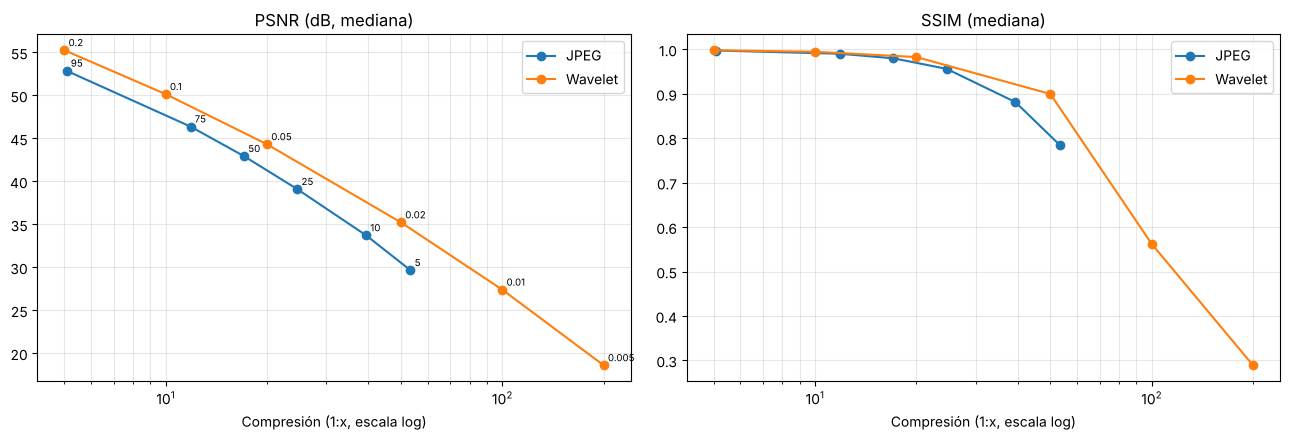

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = calidad.loc[metodo]
    axs[0].plot(d["Compresion"], d["PSNR"], "o-", color=color, label=metodo)
    axs[1].plot(d["Compresion"], d["SSIM"], "o-", color=color, label=metodo)
    for nivel, r in d.iterrows():
        axs[0].annotate(nivel, (r["Compresion"], r["PSNR"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
for ax, t in zip(axs, ["PSNR (dB, mediana)", "SSIM (mediana)"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

&ensp; La compresión se mide respecto de la imagen sin comprimir a 8 bpp. Como referencia, los PNG originales (sin pérdida) ocupan una mediana de **4,41 bpp (1:1,8)**.

| Método | Nivel | Compresión (mediana) | PSNR (dB) | SSIM |
|---|---|---|---|---|
| JPEG | q = 95 | 1:5,1 | 52,9 | 0,998 |
| JPEG | q = 75 | 1:11,8 | 46,4 | 0,990 |
| JPEG | q = 50 | 1:17,1 | 42,9 | 0,980 |
| JPEG | q = 25 | 1:24,6 | 39,1 | 0,956 |
| JPEG | q = 10 | 1:39,4 | 33,7 | 0,881 |
| JPEG | q = 5 | 1:53,3 | 29,7 | 0,785 |
| Wavelet | 20 % | 1:5 | 55,3 | 0,998 |
| Wavelet | 10 % | 1:10 | 50,1 | 0,995 |
| Wavelet | 5 % | 1:20 | 44,3 | 0,983 |
| Wavelet | 2 % | 1:50 | 35,2 | 0,900 |
| Wavelet | 1 % | 1:100 | 27,4 | 0,562 |
| Wavelet | 0,5 % | 1:200 | 18,6 | 0,289 |

**Resultados.**
- Las dos métricas caen de forma monótona con la compresión. Hasta 1:25 en JPEG y 1:20 en wavelets, el PSNR se mantiene por encima de 39 dB y el SSIM por encima de 0,95.
- A igual tasa nominal, las wavelets dan mayor PSNR y SSIM que JPEG hasta 1:20 (44,3 dB a 1:20 contra 42,9 dB de JPEG a 1:17), pero caen más rápido después: SSIM de 0,562 a 1:100, por la pérdida de la banda de aproximación. Esta comparación favorece a las wavelets, porque su tasa es nominal (6.3).
- Los percentiles 10 están cerca de las medianas salvo en los niveles extremos (SSIM P10 = 0,625 en JPEG q = 5), donde algunas imágenes se degradan mucho más que otras.

**Limitaciones.** El PSNR y el SSIM se calculan sobre la imagen completa, incluido el fondo, que se comprime casi sin error y mejora las métricas. Una buena calidad global no garantiza que se conserven detalles chicos como las lesiones, y por eso en 6.6 y 6.7 se evalúa el pipeline directamente.

## 6.6 Efecto sobre la máscara y la segmentación

In [10]:
# Dice de la máscara y de la segmentación contra la versión original del mismo corte. El Dice de la segmentación
# solo se calcula cuando la original o la comprimida tienen alguna región. "Detección igual": la comprimida tiene
# alguna región si y solo si la original la tiene.
base = comp[comp["Metodo"] == "Original"].set_index("Ruta")
cmp["Area_rel_0"] = cmp["Ruta"].map(base["Area_rel"])
cmp["N_regiones_0"] = cmp["Ruta"].map(base["N_regiones"])
cmp["Deteccion_igual"] = (cmp["N_regiones"] > 0) == (cmp["N_regiones_0"] > 0)
cmp["Dif_Area_rel"] = cmp["Area_rel"] - cmp["Area_rel_0"]
cmp["Dif_N_regiones"] = cmp["N_regiones"] - cmp["N_regiones_0"]

seg = (cmp.groupby(["Metodo", "Nivel"], sort=False)
          .agg(Compresion=("Compresion", "median"),
               Dice_mascara=("Dice_mascara", "median"),
               Dice_seg_mediana=("Dice_seg", "median"), Dice_seg_media=("Dice_seg", "mean"),
               Deteccion_igual=("Deteccion_igual", "mean"),
               Dif_Area_rel_media=("Dif_Area_rel", "mean"), Dif_N_regiones_media=("Dif_N_regiones", "mean")))
print("Cortes con alguna región en la original:", (base["N_regiones"] > 0).sum(), "de", len(base))
seg.round(3)

Cortes con alguna región en la original: 135 de 300


Compresion  Dice_mascara  Dice_seg_mediana  Dice_seg_media  \
Metodo  Nivel                                                               
JPEG    95          5.077         0.999             0.993           0.933   
        75         11.846         0.999             0.969           0.865   
        50         17.084         0.998             0.950           0.798   
        25         24.593         0.998             0.904           0.762   
        10         39.383         0.995             0.716           0.553   
        5          53.319         0.992             0.101           0.275   
Wavelet 0.2         5.000         1.000             0.996           0.969   
        0.1        10.000         0.999             0.983           0.891   
        0.05       20.000         0.999             0.940           0.803   
        0.02       50.000         0.995             0.752           0.578   
        0.01      100.000         0.984             0.493           0.425   
        0.005     200.009         0.949             0.462           0.395   

               Deteccion_igual  Dif_Area_rel_media  Dif_N_regiones_media  
Metodo  Nivel                                                             
JPEG    95               0.980              -0.000                 0.013  
        75               0.963              -0.000                -0.003  
        50               0.940              -0.000                -0.017  
        25               0.937              -0.000                -0.010  
        10               0.863               0.002                 0.323  
        5                0.713               0.010                 1.153  
Wavelet 0.2              0.993               0.000                 0.017  
        0.1              0.970               0.000                 0.030  
        0.05             0.943               0.001                 0.120  
        0.02             0.860               0.003                 0.540  
        0.01             0.780               0.005                 1.003  
        0.005            0.787               0.002                -0.100

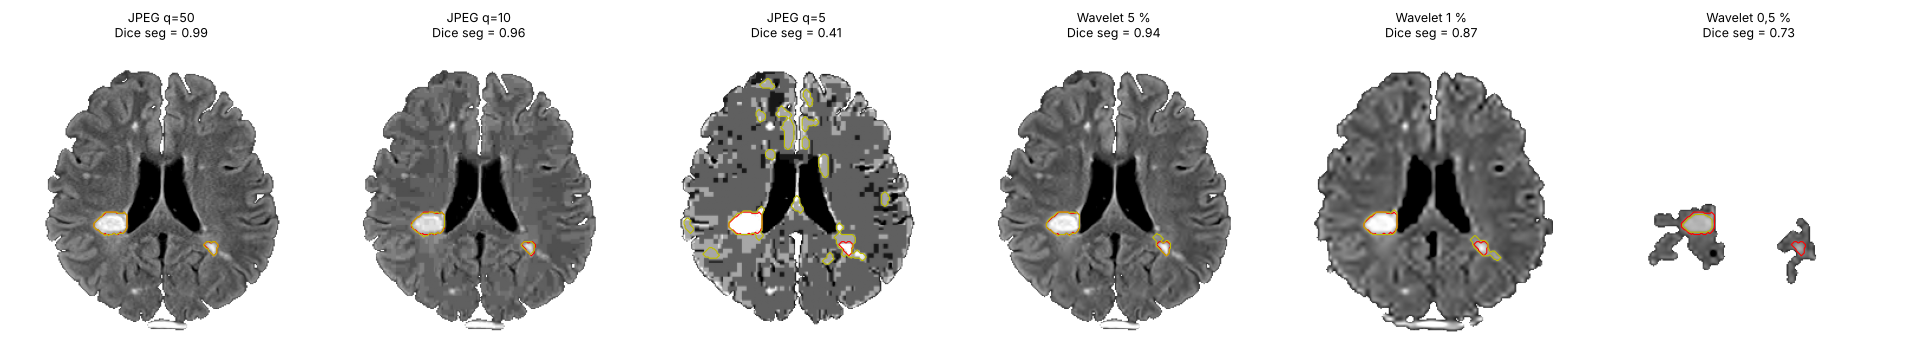

In [11]:
# Ejemplo visual: segmentación de A1 (505) a distintos niveles (rojo: original; amarillo: comprimida)
z0, m0 = preprocesar_img(img)
s0 = umbral_adaptativo(z0, m0)
versiones = [("JPEG q=50", comprimir_jpeg(img, 50)[0]), ("JPEG q=10", comprimir_jpeg(img, 10)[0]),
             ("JPEG q=5", comprimir_jpeg(img, 5)[0]), ("Wavelet 5 %", comprimir_wavelet(img, 0.05)[0]),
             ("Wavelet 1 %", comprimir_wavelet(img, 0.01)[0]), ("Wavelet 0,5 %", comprimir_wavelet(img, 0.005)[0])]
fig, axs = plt.subplots(1, len(versiones), figsize=(3.2 * len(versiones), 3.6))
for ax, (titulo, rec) in zip(axs, versiones):
    z, m = preprocesar_img(rec)
    s = umbral_adaptativo(z, m)
    ax.imshow(np.where(m, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    if s0.any(): ax.contour(s0.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    if s.any(): ax.contour(s.astype(float), levels=[0.5], colors="y", linewidths=0.8)
    ax.set_title(f"{titulo}\nDice seg = {dice(s0, s):.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

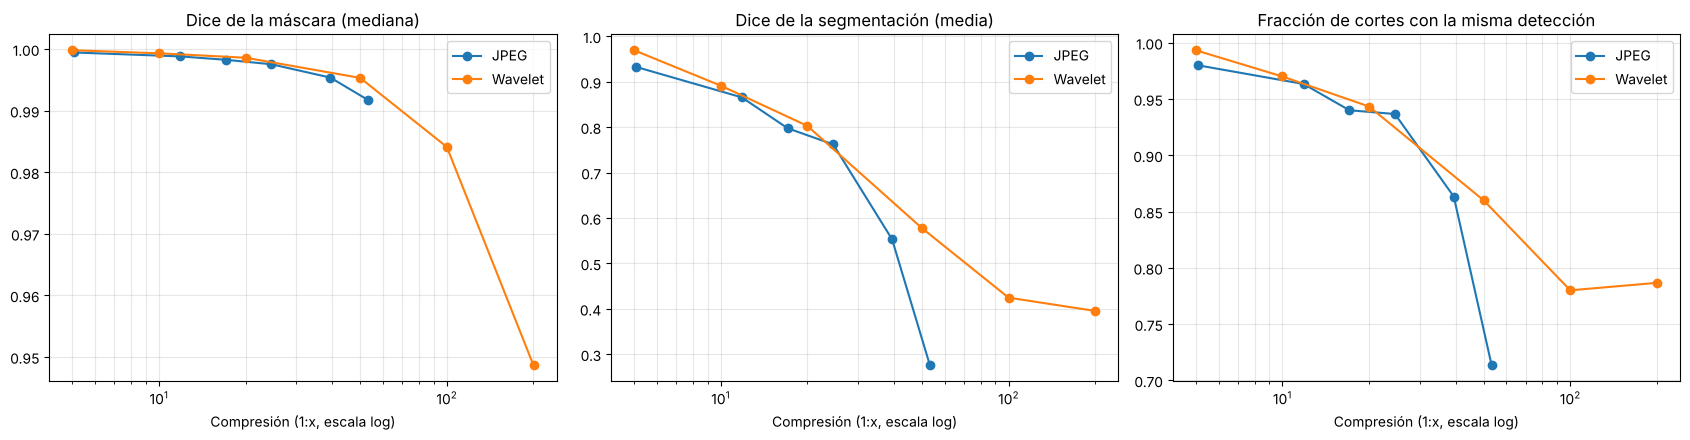

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = seg.loc[metodo]
    axs[0].plot(d["Compresion"], d["Dice_mascara"], "o-", color=color, label=metodo)
    axs[1].plot(d["Compresion"], d["Dice_seg_media"], "o-", color=color, label=metodo)
    axs[2].plot(d["Compresion"], d["Deteccion_igual"], "o-", color=color, label=metodo)
for ax, t in zip(axs, ["Dice de la máscara (mediana)", "Dice de la segmentación (media)", "Fracción de cortes con la misma detección"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

&ensp; La pregunta de fondo es si **la segmentación sobrevive a la compresión**. Como no hay ground truth, se compara cada versión comprimida con la segmentación de la original del mismo corte. De los 300 cortes, 135 tienen alguna región en la original.

| Método | Nivel | Compresión | Dice máscara | Dice seg. (media) | Dice seg. (mediana) | Misma detección | Δ N_regiones (media) |
|---|---|---|---|---|---|---|---|
| JPEG | q = 95 | 1:5,1 | 0,999 | 0,933 | 0,993 | 98,0 % | +0,01 |
| JPEG | q = 50 | 1:17,1 | 0,998 | 0,798 | 0,950 | 94,0 % | −0,02 |
| JPEG | q = 25 | 1:24,6 | 0,998 | 0,762 | 0,904 | 93,7 % | −0,01 |
| JPEG | q = 10 | 1:39,4 | 0,995 | 0,553 | 0,716 | 86,3 % | +0,32 |
| JPEG | q = 5 | 1:53,3 | 0,992 | 0,275 | 0,101 | 71,3 % | +1,15 |
| Wavelet | 10 % | 1:10 | 0,999 | 0,891 | 0,983 | 97,0 % | +0,03 |
| Wavelet | 5 % | 1:20 | 0,999 | 0,803 | 0,940 | 94,3 % | +0,12 |
| Wavelet | 2 % | 1:50 | 0,995 | 0,578 | 0,752 | 86,0 % | +0,54 |
| Wavelet | 1 % | 1:100 | 0,984 | 0,425 | 0,493 | 78,0 % | +1,00 |
| Wavelet | 0,5 % | 1:200 | 0,949 | 0,395 | 0,462 | 78,7 % | −0,10 |

**Resultados.**
- **La máscara cerebral es muy robusta**: Dice ≥ 0,98 en todos los niveles salvo wavelet 0,5 %. Otsu y la morfología trabajan sobre el contraste grueso cerebro/fondo, que la compresión conserva.
- **La segmentación es mucho más sensible.** Hasta JPEG q = 25 (1:25) y wavelet 5 % (1:20) la mediana del Dice se mantiene en ≥ 0,90 y la detección coincide en ≥ 93,7 % de los cortes. Desde ahí cae rápido.
- La media del Dice es bastante menor que la mediana: hay cortes con regiones chicas, cerca del área mínima de 50 px, que aparecen o desaparecen por completo (Dice = 0), mientras que las lesiones grandes se conservan. En el ejemplo `A1 (505)`, la lesión grande da Dice 0,99 con JPEG q = 50 y 0,96 con q = 10.
- **Con compresión fuerte aparecen falsos positivos**: `N_regiones` sube en promedio 1,15 regiones por corte con JPEG q = 5 y 1,00 con wavelet 1 %. Los bloques de JPEG y el *ringing* de las wavelets generan manchas que el umbral adaptativo toma como lesiones (se ve en el ejemplo con q = 5). Con wavelet 0,5 % el promedio vuelve a bajar porque la máscara se rompe (6.3) y hay menos cerebro donde segmentar, no porque mejore.

**Limitaciones.** «Sobrevivir» significa acá coincidir con la segmentación de la original, que tampoco está validada: el Dice no dice si la segmentación es correcta, sino si es estable. La muestra es de 300 cortes, con solo 135 que tienen alguna región.

## 6.7 Efecto sobre la clasificación

In [13]:
# El clasificador (entrenado con imágenes originales en 6.1) se aplica a las características de cada versión
comp["Eje_axial"] = (comp["Eje"] == "Axial").astype(int)
comp["y"] = (comp["Clase"] == "MS").astype(int)
comp["p"] = np.nan
ok_feat = comp[CARACTERISTICAS].notna().all(axis=1)
comp.loc[ok_feat, "p"] = clf.predict_proba(comp.loc[ok_feat, CARACTERISTICAS].to_numpy())[:, 1]
p0 = comp[comp["Metodo"] == "Original"].set_index("Ruta")["p"]
comp["Cambia_prediccion"] = (comp["p"] >= 0.5) != (comp["Ruta"].map(p0) >= 0.5)

filas = []
for (metodo, nivel), d in comp.groupby(["Metodo", "Nivel"], sort=False):
    d = d.dropna(subset=["p"])
    filas.append({"Metodo": metodo, "Nivel": nivel, "n": len(d), **metricas(d["y"].to_numpy(), d["p"].to_numpy()),
                  "% predicciones que cambian": 100 * d["Cambia_prediccion"].mean()})
clas = pd.DataFrame(filas).set_index(["Metodo", "Nivel"])
clas["Compresion"] = calidad["Compresion"].reindex(clas.index)
clas[["Compresion", "n", "AUC", "Sensibilidad", "Especificidad", "% predicciones que cambian"]].round(3)

Compresion    n    AUC  Sensibilidad  Especificidad  \
Metodo   Nivel                                                        
Original -             NaN  300  0.730         0.613          0.747   
JPEG     95          5.077  300  0.738         0.633          0.753   
         75         11.846  300  0.727         0.620          0.733   
         50         17.084  300  0.724         0.633          0.713   
         25         24.593  300  0.736         0.627          0.740   
         10         39.383  300  0.674         0.753          0.513   
         5          53.319  297  0.592         0.966          0.053   
Wavelet  0.2         5.000  300  0.730         0.607          0.747   
         0.1        10.000  300  0.726         0.613          0.727   
         0.05       20.000  300  0.710         0.580          0.727   
         0.02       50.000  300  0.686         0.573          0.740   
         0.01      100.000  300  0.682         0.547          0.740   
         0.005     200.009  285  0.661         0.358          0.818   

                % predicciones que cambian  
Metodo   Nivel                              
Original -                           0.000  
JPEG     95                          2.000  
         75                          3.667  
         50                          4.667  
         25                          5.667  
         10                         28.000  
         5                          53.872  
Wavelet  0.2                         1.000  
         0.1                         2.333  
         0.05                        6.667  
         0.02                       13.000  
         0.01                       19.667  
         0.005                      29.474

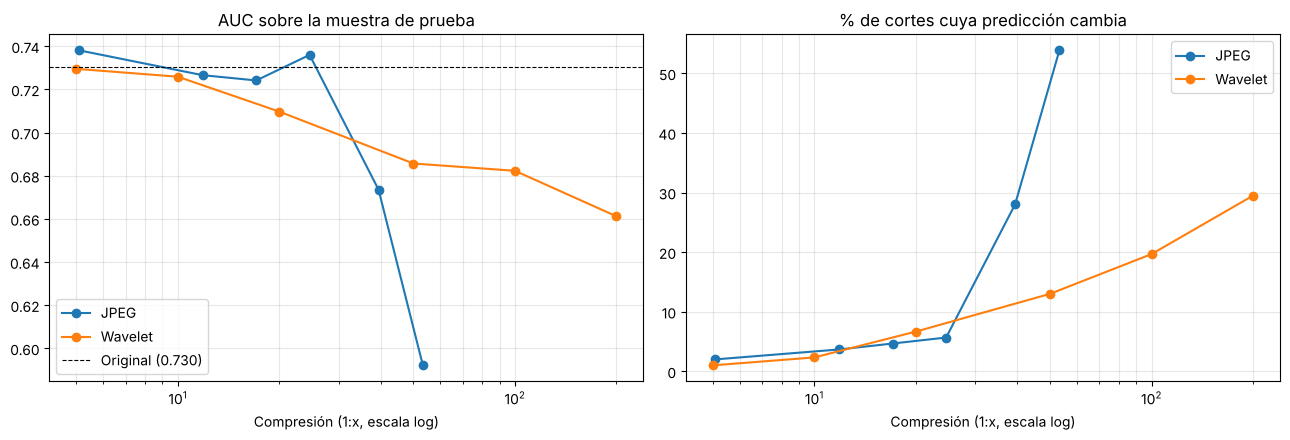

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
auc0 = clas.loc[("Original", "-"), "AUC"]
for metodo, color in [("JPEG", "tab:blue"), ("Wavelet", "tab:orange")]:
    d = clas.loc[metodo]
    axs[0].plot(d["Compresion"], d["AUC"], "o-", color=color, label=metodo)
    axs[1].plot(d["Compresion"], d["% predicciones que cambian"], "o-", color=color, label=metodo)
axs[0].axhline(auc0, color="k", ls="--", lw=0.8, label=f"Original ({auc0:.3f})")
for ax, t in zip(axs, ["AUC sobre la muestra de prueba", "% de cortes cuya predicción cambia"]):
    ax.set_xscale("log"); ax.set_xlabel("Compresión (1:x, escala log)"); ax.set_title(t)
    ax.grid(True, alpha=0.3, which="both"); ax.legend()
plt.tight_layout()
plt.show()

&ensp; El clasificador del notebook 05 (regresión logística con todas las características y `class_weight="balanced"`) se entrenó en 6.1 con las **imágenes originales** de 2209 cortes y se aplicó, sin reentrenar, a las características de cada versión de los 300 cortes de prueba. Esto simula un modelo ajustado con imágenes de calidad diagnóstica que después recibe imágenes comprimidas.

| Método | Nivel | Compresión | AUC | Sensibilidad | Especificidad | Predicciones que cambian |
|---|---|---|---|---|---|---|
| Original | — | — | 0,730 | 0,613 | 0,747 | — |
| JPEG | q = 95 | 1:5,1 | 0,738 | 0,633 | 0,753 | 2,0 % |
| JPEG | q = 50 | 1:17,1 | 0,724 | 0,633 | 0,713 | 4,7 % |
| JPEG | q = 25 | 1:24,6 | 0,736 | 0,627 | 0,740 | 5,7 % |
| JPEG | q = 10 | 1:39,4 | 0,674 | 0,753 | 0,513 | 28,0 % |
| JPEG | q = 5 | 1:53,3 | 0,592 | 0,966 | 0,053 | 53,9 % |
| Wavelet | 10 % | 1:10 | 0,726 | 0,613 | 0,727 | 2,3 % |
| Wavelet | 5 % | 1:20 | 0,710 | 0,580 | 0,727 | 6,7 % |
| Wavelet | 2 % | 1:50 | 0,686 | 0,573 | 0,740 | 13,0 % |
| Wavelet | 1 % | 1:100 | 0,682 | 0,547 | 0,740 | 19,7 % |
| Wavelet | 0,5 % | 1:200 | 0,661 | 0,358 | 0,818 | 29,5 % |

&ensp; El AUC sobre la imagen original (0,730) es menor que el de la validación cruzada del notebook 05 (0,809): estos 300 cortes son una sola partición de grupos, y con ese n el AUC tiene una incertidumbre del orden de ±0,06.

**Resultados.**
- **La clasificación sobrevive hasta JPEG q = 25 (1:25) y wavelet 5 % (1:20)**: el AUC queda entre 0,710 y 0,738, dentro de la variabilidad esperable, y cambia la predicción de menos del 7 % de los cortes.
- Con compresión más fuerte, el error **no es solo ruido sino un sesgo**, y su dirección depende del tipo de artefacto:
  - **JPEG empuja hacia MS.** Con q = 5, la sensibilidad sube a 0,966 y la especificidad cae a 0,053. Los bloques aumentan el contraste y la entropía de la textura y generan falsos positivos en la segmentación, que son justamente las características que el modelo asocia con MS (5.6).
  - **Las wavelets empujan hacia Control.** Con 0,5 %, la sensibilidad cae a 0,358. El suavizado reduce el contraste y la heterogeneidad de la sustancia blanca.
- En JPEG q = 5 y wavelet 0,5 % hay 3 y 15 cortes sin predicción, porque la región profunda quedó por debajo de 200 px y la textura es NaN.

**Limitaciones.** Se evaluó un solo modelo, entrenado con una sola partición, sobre 300 cortes. Las diferencias de AUC menores a ~0,06 no deben interpretarse.

## Resumen para src/

In [15]:
# Verificación: src/compresion.py da exactamente lo mismo que las funciones del notebook
import src.compresion as cpr

assert cpr.CALIDADES_JPEG == CALIDADES_JPEG and cpr.FRACCIONES_WAVELET == FRACCIONES_WAVELET
for ruta in muestra["Ruta"].sample(5, random_state=1):
    im = a_gris(DATA / ruta)
    for q in CALIDADES_JPEG:
        a, b = cpr.comprimir_jpeg(im, q), comprimir_jpeg(im, q)
        assert np.array_equal(a[0], b[0]) and a[1] == b[1]
    for f in FRACCIONES_WAVELET:
        a, b = cpr.comprimir_wavelet(im, f), comprimir_wavelet(im, f)
        assert np.array_equal(a[0], b[0]) and a[1] == b[1]
    z1, m1 = cpr.preprocesar_img(im); z2, m2 = preprocesar_img(im)
    assert np.array_equal(z1, z2) and np.array_equal(m1, m2)
    pd.testing.assert_frame_equal(pd.DataFrame(cpr.evaluar_corte(im)), pd.DataFrame(evaluar_corte(im)))
print("src/compresion.py coincide con el notebook")

src/compresion.py coincide con el notebook


&ensp; Se creó `src/compresion.py` con las funciones de este notebook. La celda anterior verifica sobre 5 cortes que dan **exactamente** el mismo resultado: las mismas imágenes comprimidas y tasas, el mismo preprocesamiento y la misma tabla de `evaluar_corte`.

| Función / constante | Qué hace |
|---|---|
| `CALIDADES_JPEG`, `FRACCIONES_WAVELET`, `WAVELET`, `NIVELES_WAVELET` | Niveles de compresión evaluados (`bior4.4`, 3 niveles). |
| `comprimir_jpeg(img, calidad)` | Comprime y decodifica en memoria con Pillow; devuelve la imagen y los bpp reales. |
| `comprimir_wavelet(img, fraccion)` | Umbral duro sobre los coeficientes wavelet; devuelve la imagen (uint8) y la fracción conservada (tasa nominal). |
| `calidad_imagen(original, comprimida)` | PSNR y SSIM sobre la imagen completa. |
| `preprocesar_img(img)` | Igual que `preprocesar(ruta)`, pero recibe la imagen. |
| `dice(a, b)` | Coeficiente de Dice (NaN si las dos máscaras están vacías). |
| `evaluar_corte(img)` | Pipeline completo sobre la original y los 12 niveles, con calidad, Dice y características. |

**Dependencia nueva:** `PyWavelets` (`pip install PyWavelets`). Hay que agregarlo al `requirements.txt`.

**Conclusión.** La calidad de imagen medida con PSNR y SSIM cae de forma gradual, pero el pipeline es más frágil que esas métricas: la máscara resiste casi cualquier compresión, mientras que la segmentación y la clasificación solo se mantienen estables hasta aproximadamente **1:25 con JPEG (q ≥ 25) y 1:20 con wavelets (≥ 5 % de coeficientes)**. Más allá, los artefactos no solo agregan ruido sino que **sesgan** la clasificación: JPEG hacia MS y las wavelets hacia Control. Un SSIM alto (≈ 0,96 en JPEG q = 25) no garantiza por sí solo que se conserven las lesiones chicas, que son las primeras en aparecer o desaparecer.

**Limitaciones:**
- Las imágenes del dataset ya son PNG recortados y remuestreados, no los DICOM originales, así que la compresión se aplicó sobre un material ya procesado.
- La tasa de las wavelets es nominal (sin codificación).
- Se usó una muestra de 300 cortes de una sola partición y un solo clasificador.
- Sin ground truth, «sobrevivir» significa coincidir con el resultado sobre la original, no ser correcto.